# Multiscaling in Equity Indices — Annotated Walkthrough

This is the **runnable** companion to [`../README.md`](../README.md) and
[`../docs/THEORY.md`](../docs/THEORY.md). Those explain the *reasoning*;
this notebook shows the *actual code* that implements it — every function
imported directly from [`../src/ghe.py`](../src/ghe.py) and
[`../src/synthetic.py`](../src/synthetic.py), so nothing here can drift out
of sync with the real pipeline. Each function appears three times in a row:

1. its **real source**, pulled live via `inspect.getsource` (not retyped — if the
   file changes, this notebook shows the change next time it's rerun),
2. a **line-by-line explanation** of what it does and why it's written that way,
3. a **live run** — on a tiny hand-checkable toy example first, then on real
   market data, so you can see the numbers the prose in `THEORY.md` is
   describing actually come out of the code.

Where a step in the real pipeline (`scripts/03_estimate.py`,
`scripts/04_tails.py`) uses 500 bootstrap/shuffle replicates, this notebook
uses fewer (noted at each step) purely so cells run quickly here — rerun the
real scripts for the published numbers.


## Setup

Mirrors the `sys.path` trick every script in `scripts/` uses, so this
notebook can `import ghe` and `import synthetic` directly — one estimator,
one set of validation processes, used everywhere in the project including
here.


In [1]:
import sys, os, inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT = os.path.dirname(os.getcwd())          # notebooks/ -> project root
sys.path.insert(0, os.path.join(PROJECT, "src"))

import ghe
import synthetic as sy

plt.rcParams.update({"figure.dpi": 100, "font.size": 10})
np.random.seed(0)

print("Project root:", PROJECT)
print("ghe module:   ", ghe.__file__)


Project root: /Users/eliaswatts/Desktop/Masters Applications/Masters UK/Ongoing/Kings Complex Systems and Data Modelling/multifractal
ghe module:    /Users/eliaswatts/Desktop/Masters Applications/Masters UK/Ongoing/Kings Complex Systems and Data Modelling/multifractal/src/ghe.py


## 1 — The raw material: real log prices

The project never works with raw prices — only **log prices**
(`X(t) = ln P(t)`), because that turns percent moves into additive
increments that are comparable across price levels and decades. The cleaned
data is already sitting in `data/clean/logprices.csv` (built by
`scripts/01_download.py`), so we load it rather than re-downloading.


In [2]:
lp = pd.read_csv(os.path.join(PROJECT, "data", "clean", "logprices.csv"))
sp500 = lp[lp.symbol == "^GSPC"].sort_values("date")
X = sp500["logprice"].to_numpy()

print(f"S&P 500: {len(X):,} daily log-prices, {sp500.date.iloc[0]} to {sp500.date.iloc[-1]}")
X[:5]


S&P 500: 7,178 daily log-prices, 1998-01-02 to 2026-07-17


array([6.88247847, 6.8845583 , 6.87376409, 6.87109129, 6.8628102 ])

## 2 — `structure_functions`: the engine

This is the one function everything else calls. For a series of log prices
`X` and a list of time-scales `taus`, it computes the q-th order structure
function `S_q(tau) = mean(|X[t+tau] - X[t]|^q)` for **every q in `qs` at
once** — one pass over `taus`, not one pass per q.


In [3]:
print(inspect.getsource(ghe.structure_functions))


def structure_functions(X: np.ndarray, qs: np.ndarray, taus: np.ndarray) -> np.ndarray:
    """S_q(tau) for every q at once: one pass over taus.  Shape (len(qs), len(taus))."""
    X = np.asarray(X, dtype=float)
    qs = np.asarray(qs, dtype=float)
    out = np.empty((len(qs), len(taus)), dtype=float)
    for i, tau in enumerate(taus):
        d = np.abs(X[tau:] - X[:-tau])
        logd = np.log(d, out=np.full_like(d, -np.inf), where=d > 0)
        out[:, i] = np.mean(np.exp(qs[:, None] * logd[None, :]), axis=1)
    return out



**Line by line:**

- `X = np.asarray(X, dtype=float)` — defensive cast, so the function accepts
  a plain Python list as readily as a NumPy array.
- `out = np.empty((len(qs), len(taus)), dtype=float)` — pre-allocates the
  result: one row per q, one column per tau. Filling a pre-sized array is
  faster than growing a list.
- `d = np.abs(X[tau:] - X[:-tau])` — **every** overlapping tau-day move in
  the whole series at once: `X[tau:]` is the series shifted forward by
  `tau` days, `X[:-tau]` is the original, so the subtraction is
  `X(t+tau) - X(t)` for every valid `t` simultaneously.
- `logd = np.log(d, out=np.full_like(d, -np.inf), where=d > 0)` — takes
  `log(d)` only where `d > 0`; everywhere else the output buffer is
  pre-filled with `-inf`. This sidesteps `log(0)` (which would raise a
  warning and produce `-inf` anyway) while making the *intent* explicit:
  a zero move should behave as if it contributes nothing once exponentiated
  back, for any q > 0.
- `out[:, i] = np.mean(np.exp(qs[:, None] * logd[None, :]), axis=1)` — this
  is `|d|^q` computed as `exp(q * log(d))` instead of `d ** q` directly,
  for **every q at once**: `qs[:, None]` is a column vector, `logd[None, :]`
  a row vector, so the product broadcasts into a `(len(qs), len(d))` grid —
  one row per q — before the mean collapses each row to a single number.
  Where `logd` was `-inf` (i.e. `d` was exactly 0) and `q > 0`,
  `q * -inf = -inf`, `exp(-inf) = 0` — exactly `0**q`, recovered correctly
  without ever evaluating `log(0)` directly.


In [4]:
# Toy check: five moves (one a crash day), matching the worked example in
# docs/THEORY.md section 2. Build a tiny price path whose day-to-day moves
# are exactly these five numbers.
toy_moves = np.array([0.3, -0.5, 0.2, -4.0, 0.4])
toy_X = np.concatenate([[0.0], np.cumsum(toy_moves)])

S = ghe.structure_functions(toy_X, qs=np.array([1.0, 4.0]), taus=np.array([1]))

print("S_1(tau=1) from the function:", S[0, 0])
print("S_1 by hand, mean(|moves|):  ", np.mean(np.abs(toy_moves)))
print()
print("S_4(tau=1) from the function:", S[1, 0])
print("S_4 by hand, mean(moves**4): ", np.mean(toy_moves ** 4))
print()
crash_share_q1 = abs(toy_moves[3]) ** 1 / np.sum(np.abs(toy_moves) ** 1)
crash_share_q4 = abs(toy_moves[3]) ** 4 / np.sum(np.abs(toy_moves) ** 4)
print(f"the crash day's share of the q=1 average: {crash_share_q1:.1%}")
print(f"the crash day's share of the q=4 average: {crash_share_q4:.1%}")


S_1(tau=1) from the function: 1.08
S_1 by hand, mean(|moves|):   1.08

S_4(tau=1) from the function: 51.21955999999999
S_4 by hand, mean(moves**4):  51.21956

the crash day's share of the q=1 average: 74.1%
the crash day's share of the q=4 average: 100.0%


## 3 — `_ols` and `_ols_many`: the fitting machinery

Both are plain ordinary-least-squares (straight-line) fits, done by closed
formula rather than a library call — `_ols_many` fits **many rows at once**
(one per q), `_ols` fits a single line. Every "slope" in this project —
`q·H(q)` from `log S_q(tau)` vs `log tau`, and `B` from `H(q)` vs `q` —
comes from one of these two.


In [5]:
print(inspect.getsource(ghe._ols))
print(inspect.getsource(ghe._ols_many))


def _ols(x: np.ndarray, y: np.ndarray):
    """Least squares y = a + b x. Returns (b, se_b, r2)."""
    n = len(x)
    xm, ym = x.mean(), y.mean()
    sxx = np.sum((x - xm) ** 2)
    b = np.sum((x - xm) * (y - ym)) / sxx
    a = ym - b * xm
    resid = y - (a + b * x)
    dof = n - 2
    s2 = np.sum(resid ** 2) / dof
    se_b = np.sqrt(s2 / sxx)
    ss_tot = np.sum((y - ym) ** 2)
    r2 = 1.0 - np.sum(resid ** 2) / ss_tot if ss_tot > 0 else np.nan
    return b, se_b, r2

def _ols_many(x: np.ndarray, Y: np.ndarray):
    """Least squares of each row of Y on x.  Returns (slopes, se, r2)."""
    n = len(x)
    xm = x.mean()
    sxx = np.sum((x - xm) ** 2)
    ym = Y.mean(axis=1, keepdims=True)
    b = ((Y - ym) @ (x - xm)) / sxx
    a = ym[:, 0] - b * xm
    resid = Y - (a[:, None] + b[:, None] * x[None, :])
    rss = np.sum(resid ** 2, axis=1)
    se_b = np.sqrt((rss / (n - 2)) / sxx)
    ss_tot = np.sum((Y - ym) ** 2, axis=1)
    r2 = np.where(ss_tot > 0, 1.0 - rss / ss_tot, np.nan)
    

**`_ols(x, y)` line by line:**

- `xm, ym = x.mean(), y.mean()` — the two means the slope formula is
  centred on.
- `sxx = np.sum((x - xm) ** 2)` — the sum of squared deviations in x; the
  denominator of the slope formula.
- `b = np.sum((x - xm) * (y - ym)) / sxx` — the textbook least-squares
  slope: covariance of x and y, divided by the variance of x.
- `a = ym - b * xm` — the intercept that makes the fitted line pass through
  the point of means.
- `resid = y - (a + b * x)` then `s2 = np.sum(resid ** 2) / dof` — the
  residual variance, with `dof = n - 2` because two parameters (slope,
  intercept) were already estimated from the data.
- `se_b = np.sqrt(s2 / sxx)` — the standard error of the slope: how much it
  would be expected to wobble on a fresh sample of the same size and noise
  level.
- `r2 = 1.0 - np.sum(resid ** 2) / ss_tot` — the usual R², guarded against
  division by zero when every y value is identical.

`_ols_many` is the same formula, vectorised over the first axis of `Y` so
all fifteen q-values get their own slope from one matrix expression instead
of a Python loop.


In [6]:
# Toy check: a known line, y = 2 + 3x, plus a little noise -- the fitted
# slope should land close to 3.
rng = np.random.default_rng(1)
xs = np.linspace(0, 10, 40)
ys = 2 + 3 * xs + rng.normal(0, 0.5, size=len(xs))

b, se_b, r2 = ghe._ols(xs, ys)
print(f"fitted slope   = {b:.3f}  (true slope = 3)")
print(f"standard error = {se_b:.3f}")
print(f"R-squared      = {r2:.4f}")


fitted slope   = 2.990  (true slope = 3)
standard error = 0.025
R-squared      = 0.9973


## 4 — `generalised_hurst`: the estimator itself

This puts §2 and §3 together: compute every `S_q(tau)`, take logs, fit a
line in log-log space for each q, divide the slope by q to get `H(q)`.


In [7]:
print(inspect.getsource(ghe.generalised_hurst))


def generalised_hurst(X: np.ndarray, qs, tau_max: int = 19, tau_min: int = 1):
    """H(q) for each q in qs.

    Returns dict with arrays: q, H, se (from the OLS slope only), r2.
    The standard error is the regression standard error and is *not* a valid
    confidence interval for H(q) -- the points are strongly dependent.  Use the
    block bootstrap in `block_bootstrap` for that.
    """
    qs = np.atleast_1d(np.asarray(qs, dtype=float))
    taus = np.arange(tau_min, tau_max + 1)
    S = structure_functions(X, qs, taus)
    b, se_b, r2 = _ols_many(np.log(taus), np.log(S))
    return {"q": qs, "H": b / qs, "se": se_b / qs, "r2": r2}



**Line by line:**

- `qs = np.atleast_1d(...)` — lets the function accept a single q (a scalar)
  or a whole array, uniformly.
- `taus = np.arange(tau_min, tau_max + 1)` — the fitting window from §6 of
  `THEORY.md`: by default 1 to 19 trading days inclusive.
- `S = structure_functions(X, qs, taus)` — every `S_q(tau)`, computed once.
- `b, se_b, r2 = _ols_many(np.log(taus), np.log(S))` — the log-log fit from
  §3, run for every q at once: `b` here is the slope `q·H(q)`, not `H(q)`
  itself yet.
- `return {"q": qs, "H": b / qs, ...}` — dividing the slope by q is exactly
  what undoes the exponent in `S_q(tau) ~ tau^(q·H(q))`, recovering `H(q)`.
  The docstring is explicit that `se` here is *not* a valid confidence
  interval, because consecutive `tau` values share most of their underlying
  data — `block_bootstrap` (§6 below) exists specifically to do that
  properly.


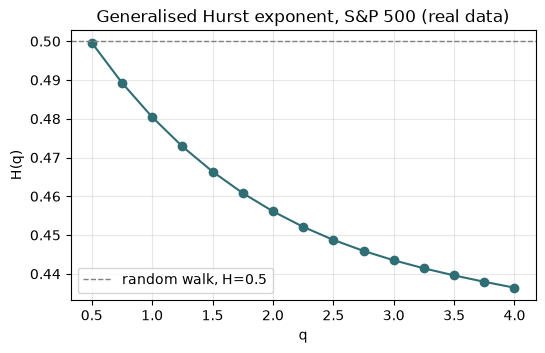

H(1) = 0.4804
H(4) = 0.4364


In [8]:
QS = np.arange(0.5, 4.01, 0.25)   # same q-grid as scripts/03_estimate.py
result = ghe.generalised_hurst(X, QS)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(result["q"], result["H"], "o-", color="#2f6e74")
ax.axhline(0.5, color="0.5", ls="--", lw=1, label="random walk, H=0.5")
ax.set_xlabel("q"); ax.set_ylabel("H(q)")
ax.set_title("Generalised Hurst exponent, S&P 500 (real data)")
ax.legend(); ax.grid(alpha=.3)
plt.show()

print(f"H(1) = {np.interp(1, result['q'], result['H']):.4f}")
print(f"H(4) = {np.interp(4, result['q'], result['H']):.4f}")


## 5 — `multiscaling_strength` and `h1_minus_h4`: one number per market

A whole `H(q)` curve is unwieldy to rank 22 countries by, so the project
fits *another* straight line through it, `H(q) = A - B·q`, and reports the
sign-flipped slope `B`. `h1_minus_h4` is a simpler cross-check that just
reads off `H(1) - H(4)` directly.


In [9]:
print(inspect.getsource(ghe.multiscaling_strength))
print(inspect.getsource(ghe.h1_minus_h4))


def multiscaling_strength(qs: np.ndarray, H: np.ndarray) -> float:
    """B in the linear fit H(q) = A - B q.  Larger B = stronger multiscaling."""
    b, _, _ = _ols(np.asarray(qs, float), np.asarray(H, float))
    return -b

def h1_minus_h4(qs: np.ndarray, H: np.ndarray) -> float:
    """H(1) - H(4), the simple multiscaling proxy used in Di Matteo et al.

    Raises if qs does not span [1, 4]: np.interp would otherwise clip
    silently to the nearest boundary value instead of extrapolating,
    returning a mislabelled H(1)-H(2)-or-similar with no warning.
    """
    qs = np.asarray(qs, float)
    if qs.min() > 1.0 or qs.max() < 4.0:
        raise ValueError(
            f"h1_minus_h4 needs qs to span [1, 4]; got [{qs.min()}, {qs.max()}]"
        )
    return float(np.interp(1.0, qs, H) - np.interp(4.0, qs, H))



**Notes:**

- `multiscaling_strength` calls `_ols(qs, H)` from §3 and returns `-b` — a
  *positive* B now means a *falling* H(q) curve (stronger multiscaling),
  which is the more intuitive sign convention for the ranking charts.
- `h1_minus_h4` was fixed during code review (see the project's commit
  history / `docs/THEORY.md` footnotes) to **raise** rather than silently
  return a wrong number if `qs` doesn't actually span `[1, 4]` — try it
  below with a deliberately too-narrow range to see the guard fire.


In [10]:
B = ghe.multiscaling_strength(result["q"], result["H"])
D = ghe.h1_minus_h4(result["q"], result["H"])
print(f"S&P 500:  B = {B:.4f}   D = H(1)-H(4) = {D:.4f}")

# the guard added in code review, firing as intended:
try:
    narrow_q = np.arange(0.5, 2.01, 0.25)
    narrow_H = ghe.generalised_hurst(X, narrow_q)["H"]
    ghe.h1_minus_h4(narrow_q, narrow_H)
except ValueError as e:
    print("\nguard fired correctly:", e)


S&P 500:  B = 0.0169   D = H(1)-H(4) = 0.0440

guard fired correctly: h1_minus_h4 needs qs to span [1, 4]; got [0.5, 2.0]


## 6 — Validating the estimator: `synthetic.py`

Before trusting `H(q)` on real data, the project runs it on processes whose
*true* `H(q)` is known exactly. `brownian_motion` and `fractional_bm` are
flat-H negative controls (monofractal by construction); `mrw` (the
Bacry–Delour–Muzy multifractal random walk) is the positive control — a
process that is genuinely, provably multifractal.


In [11]:
print(inspect.getsource(sy.brownian_motion))
print(inspect.getsource(sy.mrw_theory_H))


def brownian_motion(n: int, rng) -> np.ndarray:
    return np.concatenate([[0.0], np.cumsum(rng.standard_normal(n))])

def mrw_theory_H(q, lam2: float = 0.02) -> np.ndarray:
    q = np.asarray(q, float)
    return 0.5 + lam2 - lam2 * q / 2.0



**`brownian_motion`** is the simplest possible case: `cumsum` of
independent Gaussian noise — by definition memoryless, so its true `H(q)`
is flat at exactly 0.5 for every q.

**`mrw_theory_H(q, lam2)`** is the *known-by-construction* answer for the
multifractal random walk: `H(q) = 0.5 + lam2 - lam2*q/2` — a straight line
in q with slope `-lam2/2`, i.e. true `B = lam2/2`. The actual simulator
(`sy.mrw`, which multiplies Gaussian noise by a log-correlated random
volatility field — see `docs/THEORY.md` §5 for why building it requires
clipping a few numerically-negative eigenvalues) is more involved; this
notebook runs it below rather than reprinting its full source.


In [12]:
# Reduced replicate count for notebook speed (scripts/02_controls.py uses 300).
NREP = 30
N = 3000   # shorter series than real data (~7000) for speed; biases are the
           # same shape, just noisier -- see scripts/02_controls.py for n=7000

def run_case(generator, label, true_B):
    Bs = []
    for s in range(NREP):
        Xc = generator(np.random.default_rng(1000 + s))
        r = ghe.generalised_hurst(Xc, QS, tau_max=19)
        Bs.append(ghe.multiscaling_strength(QS, r["H"]))
    Bs = np.array(Bs)
    print(f"{label:28s} mean B = {Bs.mean():+.4f} +/- {Bs.std():.4f}   (true B = {true_B})")
    return Bs

print(f"{NREP} replicates each, n={N} points (real pipeline: 300 reps, n~7000):\n")
bm_B  = run_case(lambda r: sy.brownian_motion(N, r), "Brownian motion (H=0.5)", 0.0)
mrw_B = run_case(lambda r: sy.mrw(N, lam2=0.04, L=1024, rng=r), "MRW, lambda^2=0.04", 0.02)

print(f"\nMRW recovery: {mrw_B.mean()/0.02:.1%} of the true strength "
      f"(README/THEORY.md report ~66% at n=7000 -- a shorter series here is noisier but the same direction)")


30 replicates each, n=3000 points (real pipeline: 300 reps, n~7000):

Brownian motion (H=0.5)      mean B = +0.0000 +/- 0.0049   (true B = 0.0)
MRW, lambda^2=0.04           mean B = +0.0114 +/- 0.0143   (true B = 0.02)

MRW recovery: 57.2% of the true strength (README/THEORY.md report ~66% at n=7000 -- a shorter series here is noisier but the same direction)


## 7 — `block_bootstrap`: how uncertain is B?

Resamples whole **blocks** of daily increments (not individual days) with
replacement, rebuilds a price path, and re-estimates `B` — repeatedly — to
build a confidence interval. Blocks (not single days) are resampled so that
short-range volatility clustering survives *within* a block.


In [13]:
print(inspect.getsource(ghe.circular_block_bootstrap))
print(inspect.getsource(ghe.block_bootstrap))


def circular_block_bootstrap(increments: np.ndarray, block: int, rng) -> np.ndarray:
    """One circular-block-bootstrap resample of an increment series."""
    n = len(increments)
    nblocks = int(np.ceil(n / block))
    starts = rng.integers(0, n, size=nblocks)
    idx = (starts[:, None] + np.arange(block)[None, :]).ravel()[:n] % n
    return increments[idx]

def block_bootstrap(X: np.ndarray, qs, tau_max: int = 19, n_boot: int = 500,
                    block: int | None = None, seed: int = 0):
    """Block-bootstrap CIs for H(q) and for the multiscaling summaries.

    Resamples blocks of *increments* (returns), rebuilds a price path by
    cumulative sum, and re-estimates.  Block length defaults to
    max(20, round(n^{1/3})) -- the floor dominates at the sample sizes used
    here (n~7000 gives n^{1/3}~19.1, so every market in this project is
    bootstrapped with block=20) -- long enough to preserve the volatility
    clustering that generates the multiscaling.
    """
    X = 

**`circular_block_bootstrap` line by line:**

- `nblocks = int(np.ceil(n / block))` — enough blocks to cover (and
  slightly overshoot) the original length.
- `starts = rng.integers(0, n, size=nblocks)` — a random starting day for
  each block, drawn **with** replacement, so the same stretch of days can
  appear more than once (or not at all) in a resample.
- `idx = (starts[:, None] + np.arange(block)[None, :]).ravel()[:n] % n` —
  for each start, lays out `block` consecutive day-indices after it; `% n`
  makes the indexing wrap circularly past the end of the series (so a block
  starting near the end doesn't simply run off the array); `.ravel()[:n]`
  flattens all blocks into one long sequence and trims it to exactly the
  original length.

**`block_bootstrap`** then does this 500 times by default (fewer here, see
below): resample, turn the resampled increments back into a price path with
`np.cumsum`, run `generalised_hurst` again, record `B` and `D`. The spread
across those 500 runs *is* the confidence interval.


In [14]:
N_BOOT = 60   # real pipeline uses 500; reduced here for notebook speed
boot = ghe.block_bootstrap(X, QS, tau_max=19, n_boot=N_BOOT, seed=0)

print(f"S&P 500, {N_BOOT} block-bootstrap replicates (block length = {boot['block']} days):")
print(f"  B point estimate : {B:.4f}")
print(f"  95% CI           : [{np.percentile(boot['B'], 2.5):.4f}, {np.percentile(boot['B'], 97.5):.4f}]")


S&P 500, 60 block-bootstrap replicates (block length = 20 days):
  B point estimate : 0.0169
  95% CI           : [0.0090, 0.0447]


## 8 — `shuffle_surrogates`: the null distribution

Randomly **permutes** individual days (not blocks), which destroys all
temporal order while keeping the one-day return distribution — and
therefore kurtosis — exactly unchanged. Whatever multiscaling survives that
is definitionally not about dynamics.


In [15]:
print(inspect.getsource(ghe.shuffle_surrogates))


def shuffle_surrogates(X: np.ndarray, qs, tau_max: int = 19, n_surr: int = 500,
                       seed: int = 0):
    """Shuffle the increments (destroys all temporal structure, keeps the
    marginal distribution exactly).  Any multiscaling left is an artefact of
    fat tails and finite samples, not of the dynamics."""
    X = np.asarray(X, float)
    d = np.diff(X)
    rng = np.random.default_rng(seed)
    qs = np.atleast_1d(np.asarray(qs, float))
    B = np.empty(n_surr)
    D = np.empty(n_surr)
    Hs = np.empty((n_surr, len(qs)))
    for s in range(n_surr):
        dd = rng.permutation(d)
        Xs = np.concatenate([[0.0], np.cumsum(dd)])
        res = generalised_hurst(Xs, qs, tau_max=tau_max)
        Hs[s] = res["H"]
        B[s] = multiscaling_strength(qs, res["H"])
        D[s] = h1_minus_h4(qs, res["H"])
    return {"H": Hs, "B": B, "D": D}



Nearly identical structure to `block_bootstrap`, with one
deliberate difference: `rng.permutation(d)` shuffles every individual
increment independently, rather than resampling contiguous blocks — the
whole point is to destroy the short-range order that `block_bootstrap`
was built to preserve.


In [16]:
N_SURR = 60   # real pipeline uses 500
surr = ghe.shuffle_surrogates(X, QS, tau_max=19, n_surr=N_SURR, seed=7)

p_vs_shuffle = float((surr["B"] >= B).mean())
print(f"S&P 500 observed B        : {B:.4f}")
print(f"shuffled-surrogate mean B : {surr['B'].mean():.4f}")
print(f"fraction of shuffles with B >= observed : {p_vs_shuffle:.3f}")
print("\n(docs/THEORY.md section 8: shuffling tends to INCREASE this statistic --")
print(" a marginal-matched benchmark, not a one-sided null -- which is exactly")
print(f" what's happening here: shuffled mean ({surr['B'].mean():.4f}) > observed ({B:.4f}))")


S&P 500 observed B        : 0.0169
shuffled-surrogate mean B : 0.0501
fraction of shuffles with B >= observed : 1.000

(docs/THEORY.md section 8: shuffling tends to INCREASE this statistic --
 a marginal-matched benchmark, not a one-sided null -- which is exactly
 what's happening here: shuffled mean (0.0501) > observed (0.0169))


## 9 — Two real markets, side by side

Everything above ran on the S&P 500 alone. Here's the same pipeline on a
second market — Malaysia, the strongest multiscaler in the full 22-market
study — run through exactly the same four functions, so the shape of the
difference is visible directly rather than just reported.


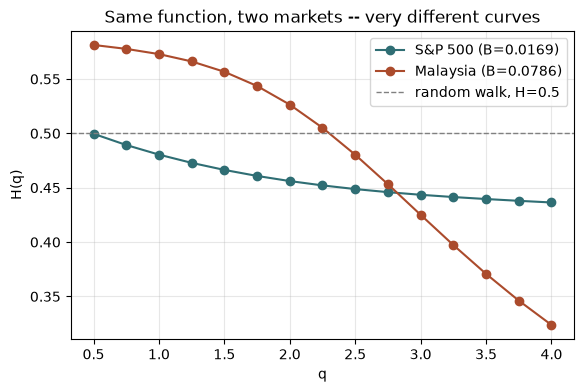

S&P 500 (developed):  B = 0.0169
Malaysia (emerging):  B = 0.0786

Same code, same q-grid, same tau window -- the gap is in the data, not the method.


In [17]:
malaysia = lp[lp.symbol == "^KLSE"].sort_values("date")
X_my = malaysia["logprice"].to_numpy()

r_my = ghe.generalised_hurst(X_my, QS, tau_max=19)
B_my = ghe.multiscaling_strength(QS, r_my["H"])

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(result["q"], result["H"], "o-", color="#2f6e74", label=f"S&P 500 (B={B:.4f})")
ax.plot(r_my["q"], r_my["H"], "o-", color="#ab4b2c", label=f"Malaysia (B={B_my:.4f})")
ax.axhline(0.5, color="0.5", ls="--", lw=1, label="random walk, H=0.5")
ax.set_xlabel("q"); ax.set_ylabel("H(q)")
ax.set_title("Same function, two markets -- very different curves")
ax.legend(); ax.grid(alpha=.3)
plt.show()

print(f"S&P 500 (developed):  B = {B:.4f}")
print(f"Malaysia (emerging):  B = {B_my:.4f}")
print(f"\nSame code, same q-grid, same tau window -- the gap is in the data, not the method.")


## Where to go next

- **The full 22-market run** (500 bootstrap/shuffle replicates, every
  robustness check): `python scripts/03_estimate.py` then
  `scripts/04_tails.py`, from the project root.
- **The conceptual deep-dive** — kurtosis, Mann-Whitney, why the shuffle
  isn't a fair null, every piece of reasoning behind the choices made
  above: [`../docs/THEORY.md`](../docs/THEORY.md).
- **The headline result, in two minutes**: [`../README.md`](../README.md).
- **The estimator's full source**, outside the function-by-function view
  above: [`../src/ghe.py`](../src/ghe.py) and
  [`../src/synthetic.py`](../src/synthetic.py).
